# 🧹 Data Cleaning with Pandas: Customer Call List

**Author:** Damilola Ogundiran

## The problem
A company's sales team wants to call its customers, but the customer list is messy: it has duplicate rows, an irrelevant column, stray symbols in names, phone numbers in five different formats, inconsistent Yes/No values, and customers who asked **not** to be contacted.

## The goal
Turn the raw list into a clean, ready-to-use **call list**, using Python and pandas.

## What this notebook covers
1. Loading and inspecting the data
2. Removing duplicate rows
3. Dropping an unneeded column
4. Cleaning stray characters from names
5. Standardizing phone numbers
6. Splitting addresses into separate columns
7. Standardizing Yes/No values
8. Filtering out customers who can't be called
9. Exporting the cleaned data

## 1. Setup and loading the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Running this in Google Colab?** Run the next cell and upload `Customer Call List.xlsx` when prompted. If you're running locally with the file in the same folder, you can skip it.

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Not running in Colab - reading the file from the current folder.")

Not running in Colab - reading the file from the current folder.


In [3]:
df = pd.read_excel("Customer Call List.xlsx")
df

,CustomerID,First_Name,Last_Name,Phone_Number,Address,Paying Customer,Do_Not_Contact,Not_Useful_Column
0,1001,Frodo,Baggins,123-545-5421,"123 Shire Lane, Shire",Yes,No,True
1,1002,Abed,Nadir,123/643/9775,93 West Main Street,No,Yes,False
2,1003,Walter,/White,7066950392,298 Drugs Driveway,N,NaN,True
3,1004,Dwight,Schrute,123-543-2345,"980 Paper Avenue, Pennsylvania, 18503",Yes,Y,True
4,1005,Jon,Snow,876|678|3469,123 Dragons Road,Y,No,True
5,1006,Ron,Swanson,304-762-2467,768 City Parkway,Yes,Yes,True
6,1007,Jeff,Winger,NaN,1209 South Street,No,No,False
7,1008,Sherlock,Holmes,876|678|3469,98 Clue Drive,N,No,False
8,1009,Gandalf,NaN,N/a,123 Middle Earth,Yes,NaN,False
9,1010,Peter,Parker,123-545-5421,"25th Main Street, New York",Yes,No,True


### First look
Before changing anything, it helps to see the shape of the data, the column types, and where values are missing.

In [4]:
print("Rows, columns:", df.shape)
df.info()

Rows, columns: (21, 8)
<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         21 non-null     int64 
 1   First_Name         21 non-null     str   
 2   Last_Name          20 non-null     str   
 3   Phone_Number       19 non-null     object
 4   Address            21 non-null     str   
 5   Paying Customer    21 non-null     str   
 6   Do_Not_Contact     17 non-null     str   
 7   Not_Useful_Column  21 non-null     bool  
dtypes: bool(1), int64(1), object(1), str(5)
memory usage: 1.3+ KB


In [5]:
# Missing values per column
df.isna().sum()

CustomerID           0
First_Name           0
Last_Name            1
Phone_Number         2
Address              0
Paying Customer      0
Do_Not_Contact       4
Not_Useful_Column    0
dtype: int64

Some problems are already visible in the table above:

- **Customer 1020 (Anakin Skywalker)** appears twice.
- `Not_Useful_Column` has nothing to do with calling customers.
- Last names contain stray characters: `/White`, `...Potter`, `Flenderson_`.
- Phone numbers use dashes, slashes, pipes, no separators, or `N/a`.
- Addresses mix street, state, and zip code in one column.
- `Paying Customer` and `Do_Not_Contact` mix `Yes`/`Y` and `No`/`N`.

We'll also track the row count after each step so we can see the effect of the cleaning.

In [6]:
row_counts = {"Raw data": len(df)}

## 2. Remove duplicate rows
`drop_duplicates()` removes rows that are identical across every column.

In [7]:
df = df.drop_duplicates()
row_counts["After removing duplicates"] = len(df)
print(f"Rows after removing duplicates: {len(df)}")

Rows after removing duplicates: 20


## 3. Drop the column we don't need

In [8]:
df = df.drop(columns="Not_Useful_Column")
df.columns.tolist()

['CustomerID',
 'First_Name',
 'Last_Name',
 'Phone_Number',
 'Address',
 'Paying Customer',
 'Do_Not_Contact']

## 4. Clean the last names
`str.strip()` removes the listed characters from **both** ends of the text. Its relatives work on one side only: `lstrip()` cleans the left, `rstrip()` cleans the right.

Here we strip dots, underscores, slashes, and spaces in a single step.

In [9]:
df["Last_Name"] = df["Last_Name"].str.strip("._/ ")
df[["First_Name", "Last_Name"]]

,First_Name,Last_Name
0,Frodo,Baggins
1,Abed,Nadir
2,Walter,White
3,Dwight,Schrute
4,Jon,Snow
5,Ron,Swanson
6,Jeff,Winger
7,Sherlock,Holmes
8,Gandalf,NaN
9,Peter,Parker


## 5. Standardize phone numbers
The phone numbers come in several formats:`123-545-5421`, `123/643/9775`, `876|678|3469`, `7066950392`, `N/a`, and blanks.

The plan:
1. Fill blanks with empty text and convert everything to text.
2. Remove every character that isn't a digit.
3. Format valid 10-digit numbers as `XXX-XXX-XXXX`.
4. Mark anything else as missing.

In [10]:
digits = df["Phone_Number"].fillna("").astype(str).str.replace(r"[^0-9]", "", regex=True)

def format_phone(number):
    if len(number) == 10:
        return f"{number[:3]}-{number[3:6]}-{number[6:]}"
    return np.nan

df["Phone_Number"] = digits.apply(format_phone)
df[["First_Name", "Last_Name", "Phone_Number"]]

,First_Name,Last_Name,Phone_Number
0,Frodo,Baggins,123-545-5421
1,Abed,Nadir,123-643-9775
2,Walter,White,706-695-0392
3,Dwight,Schrute,123-543-2345
4,Jon,Snow,876-678-3469
5,Ron,Swanson,304-762-2467
6,Jeff,Winger,NaN
7,Sherlock,Holmes,876-678-3469
8,Gandalf,NaN,NaN
9,Peter,Parker,123-545-5421


## 6. Split the address into separate columns
Some addresses include a state and zip code after commas, e.g. `980 Paper Avenue, Pennsylvania, 18503`. Splitting on the comma gives each piece its own column, which makes filtering by location much easier.

In [11]:
df["Address"] = df["Address"].replace("N/a", np.nan)

address_parts = df["Address"].str.split(",", n=2, expand=True)
df["Street_Address"] = address_parts[0].str.strip()
df["State"] = address_parts[1].str.strip()
df["Zip_Code"] = address_parts[2].str.strip()

df = df.drop(columns="Address")
df[["Street_Address", "State", "Zip_Code"]]

,Street_Address,State,Zip_Code
0,123 Shire Lane,Shire,NaN
1,93 West Main Street,NaN,NaN
2,298 Drugs Driveway,NaN,NaN
3,980 Paper Avenue,Pennsylvania,18503
4,123 Dragons Road,NaN,NaN
5,768 City Parkway,NaN,NaN
6,1209 South Street,NaN,NaN
7,98 Clue Drive,NaN,NaN
8,123 Middle Earth,NaN,NaN
9,25th Main Street,New York,NaN


## 7. Standardize Yes/No values
`Paying Customer` and `Do_Not_Contact` use both full words and single letters. We map everything to `Yes` or `No`, and treat `N/a` as missing.

In [12]:
yes_no_map = {"Y": "Yes", "N": "No", "N/a": np.nan}

for col in ["Paying Customer", "Do_Not_Contact"]:
    df[col] = df[col].replace(yes_no_map)
    print(col, "->", df[col].value_counts(dropna=False).to_dict())

Paying Customer -> {'Yes': 13, 'No': 6, nan: 1}
Do_Not_Contact -> {'No': 12, 'Yes': 4, nan: 4}


## 8. Build the final call list
The sales team can only call a customer if:

- they have a **valid phone number**, and
- they have **not** asked to be left alone (`Do_Not_Contact` is not `Yes`).

Customers with a blank `Do_Not_Contact` value are kept, since they never opted out.

In [13]:
call_list = df[
    df["Phone_Number"].notna() & (df["Do_Not_Contact"] != "Yes")
].reset_index(drop=True)

row_counts["Final call list"] = len(call_list)
call_list

,CustomerID,First_Name,Last_Name,Phone_Number,Paying Customer,Do_Not_Contact,Street_Address,State,Zip_Code
0,1001,Frodo,Baggins,123-545-5421,Yes,No,123 Shire Lane,Shire,NaN
1,1003,Walter,White,706-695-0392,No,NaN,298 Drugs Driveway,NaN,NaN
2,1005,Jon,Snow,876-678-3469,Yes,No,123 Dragons Road,NaN,NaN
3,1008,Sherlock,Holmes,876-678-3469,No,No,98 Clue Drive,NaN,NaN
4,1010,Peter,Parker,123-545-5421,Yes,No,25th Main Street,New York,NaN
5,1012,Harry,Potter,706-695-0392,Yes,NaN,2394 Hogwarts Avenue,NaN,NaN
6,1013,Don,Draper,123-543-2345,Yes,No,2039 Main Street,NaN,NaN
7,1014,Leslie,Knope,876-678-3469,Yes,No,343 City Parkway,NaN,NaN
8,1015,Toby,Flenderson,304-762-2467,No,No,214 HR Avenue,NaN,NaN
9,1016,Ron,Weasley,123-545-5421,No,No,2395 Hogwarts Avenue,NaN,NaN


## 9. Before vs. after

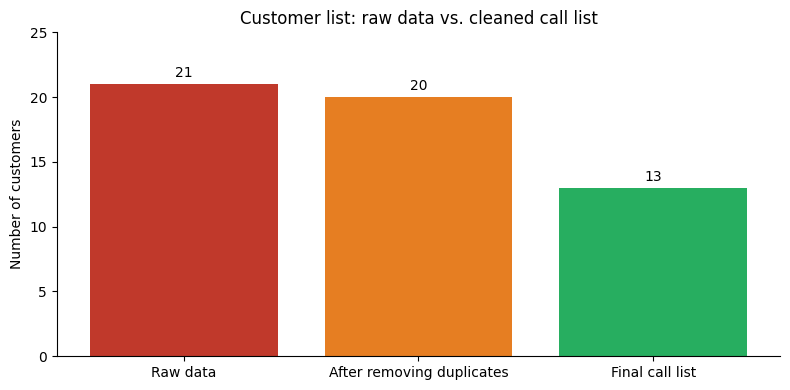

Started with 21 rows and ended with 13 callable customers.


In [14]:
steps = list(row_counts.keys())
counts = list(row_counts.values())

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(steps, counts, color=["#c0392b", "#e67e22", "#27ae60"])
ax.bar_label(bars, padding=3)
ax.set_ylabel("Number of customers")
ax.set_title("Customer list: raw data vs. cleaned call list")
ax.set_ylim(0, max(counts) + 4)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Started with {counts[0]} rows and ended with {counts[-1]} callable customers.")

## 10. Export the results

In [15]:
df.to_excel("Cleaned_Customer_List_Full.xlsx", index=False)
call_list.to_excel("Final_Call_List.xlsx", index=False)
print("Saved: Cleaned_Customer_List_Full.xlsx and Final_Call_List.xlsx")

Saved: Cleaned_Customer_List_Full.xlsx and Final_Call_List.xlsx


## Key takeaways
- **`drop_duplicates()`** and **`drop(columns=...)`** handle the quick wins.
- **`str.strip()`** cleans unwanted characters from the ends of text.
- **`str.replace()` with regex** is the fastest way to standardize messy formats like phone numbers.
- **`str.split(expand=True)`** turns one crowded column into several useful ones.
- **`replace()` with a dictionary** makes inconsistent categories consistent.
- **Boolean filtering** turns a cleaned dataset into a list the business can act on.

*Thanks for reading! Feedback and suggestions are welcome.*